# OGM model v2 — results

Visualises the output of `experiments.py`; it runs no simulations. Regenerate the data with

```bash
python experiments.py            # writes data/trials.csv and data/params.json
```

**Framing.** Everyone retrieves with a successor-feature (SF) learner; people differ in how much of the blame for an aversive memory goes to *retrieval in general* (a bias feature active on every step, learning rate `alpha_bias`) rather than to the memory's *content*. `alpha_bias = 0` keeps value tied to content; the single-value (SV) agent is the other pole, where only retrieval-in-general carries value. Value decay lets learned avoidance fade.

**Protocol (every run).** Healthy warm-up with no trauma memory → trauma onset (a new 20-memory group, one memory of valence −50) → measured retrievals, each cued by the trauma group with probability 0.25, otherwise by a random group. Every retrieval is scored like the Autobiographical Memory Test: **specific** (ended on an event memory), **categoric** (ended on a general-event summary) or **omission** (nothing retrieved).

**Which cues are shown.** Retrievals cued by a group other than the trauma's (*other cues*) are the analogue of AMT cue words: generic, not about the trauma. Trauma cues stand for everyday reminders; they keep the trauma in the agent's learning stream but have no AMT counterpart. Figures and tables therefore show other cues only; section 6 compares the two as a check.

Error bars and bands are 95% confidence intervals across seeds (t-based; one value per seed).

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

DATA_DIR = os.environ.get("OGM_DATA", "data")
trials = pd.read_csv(os.path.join(DATA_DIR, "trials.csv"))
with open(os.path.join(DATA_DIR, "params.json")) as f:
    params = json.load(f)

OUTCOMES = ["specific", "categoric", "omission"]
# Reference categorical palette, slots 1-3 (validated all-pairs, light mode).
# Colour always means outcome in this notebook; agents and conditions are panels.
OUTCOME_COLORS = {"specific": "#2a78d6", "categoric": "#eb6834", "omission": "#1baf7a"}
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})

# Older trials.csv files predate alpha_content: SF learned content at alpha_w,
# SV has no content features.
if "alpha_content" not in trials:
    trials["alpha_content"] = np.where(trials["agent"] == "SV", 0.0, params["alpha_w"])
# Position on the merged spectrum (content_share) for older trials.csv files.
if "content_share" not in trials:
    total = trials["alpha_bias"].fillna(0) + trials["alpha_content"]
    trials["content_share"] = np.where(trials["agent"] == "SV", 0.0,
                                       (trials["alpha_content"] / total.where(total > 0)).round(10))
    trials["on_spectrum"] = (trials["agent"] == "SV") | np.isclose(total, params["alpha_w"])
# Spectrum position as one label: SF's alpha_bias (plus " c<rate>" when its
# content learning rate was lowered from alpha_w), or "SV" for the pole.
content_tag = np.where(trials["alpha_content"] != params["alpha_w"],
                       " c" + trials["alpha_content"].map(lambda a: f"{a:g}"), "")
trials["spectrum"] = np.where(trials["agent"] == "SV", "SV",
                              "SF " + trials["alpha_bias"].map(lambda a: f"{a:g}") + content_tag)
# Main and sensitivity use the default trauma valence and categoric payoff;
# the severity sweep (section 4) varies them.
default = ((trials["trauma_valence"] == params["trauma_valence"])
           & (trials["summary_report"] == params["summary_report"]))
# Sections 2-4 use runs with the default measured-phase length; the time
# course (section 5) uses its own, longer runs.
measured = trials[(trials["phase"] == "measured") & (trials["run_length"] == params["measured"])].copy()
is_main = default & ((trials["agent"] == "SV") | (trials["alpha_bias"] == 0))
main = measured[is_main[measured.index] & measured["decay_rate"].isin(params["decay_rates"])]
sens = measured[default[measured.index] & (measured["decay_rate"] == params["sens_decay"])]
MAIN_LABELS = {"SV": "SV (single value)", "SF 0": "SF, alpha_bias = 0"}

print(f"{trials['seed'].nunique()} seeds; warm-up {params['warmup']} + measured {params['measured']} "
      f"retrievals per run; trauma cue p = {params['p_trauma_cue']}")
print(trials[default].groupby(["spectrum", "decay_rate"]).seed.nunique().rename("seeds").to_frame().T.to_string())

10 seeds; warm-up 150 + measured 600 retrievals per run; trauma cue p = 0.25
spectrum   SF 0           SF 0.0025 SF 0.005 SF 0.01 SF 0.02 SF 0.03 SF 0.1   SV          
decay_rate 0.00 0.01 0.02      0.01     0.01    0.01    0.01    0.01   0.01 0.00 0.01 0.02
seeds        10   10   10        10       10      10      10      10     10   10   10   10


In [2]:
def per_seed_props(df, keys):
    """Outcome proportions for each seed within each group of keys."""
    p = (df.groupby(keys + ["seed"])["outcome"].value_counts(normalize=True)
           .unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0))
    return p.reset_index()


def summarise(per_seed, keys):
    """Mean and 95% CI half-width across seeds, long format."""
    long = per_seed.melt(id_vars=keys + ["seed"], value_vars=OUTCOMES,
                         var_name="outcome", value_name="p")
    g = long.groupby(keys + ["outcome"])["p"]
    out = g.agg(mean="mean", sd="std", n="count").reset_index()
    tcrit = stats.t.ppf(0.975, (out["n"] - 1).clip(lower=1))
    out["ci"] = (tcrit * out["sd"] / np.sqrt(out["n"])).fillna(0)
    return out


def outcome_table(summary, index, columns="outcome"):
    """Readable 'mean ± ci' table (the table view for each figure)."""
    cell = summary.assign(v=summary["mean"].map("{:.2f}".format) + " ± " + summary["ci"].map("{:.2f}".format))
    return cell.pivot_table(index=index, columns=columns, values="v", aggfunc="first")[OUTCOMES]


def outcome_legend(fig, **kw):
    handles = [plt.Line2D([], [], color=OUTCOME_COLORS[o], lw=6) for o in OUTCOMES]
    fig.legend(handles, OUTCOMES, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.02), **kw)

## 1. Healthy baseline

Before trauma onset the agents retrieve under the original stop rule. Both should end the warm-up giving mostly specific memories — otherwise later non-specific retrieval could not be blamed on the trauma.

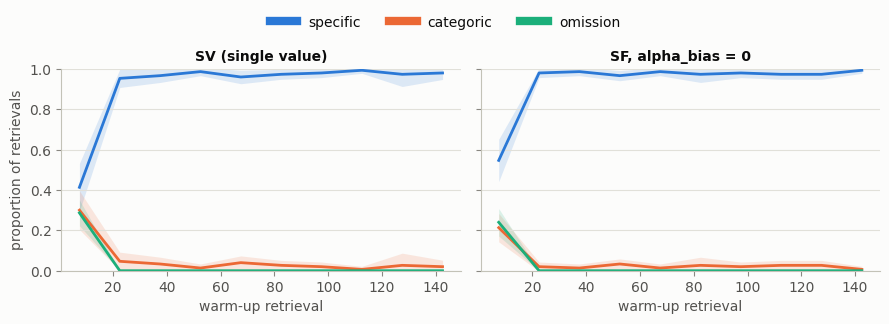

outcome,specific,categoric,omission
"warm-up, second half",,,
"SF, alpha_bias = 0",0.98 ± 0.01,0.02 ± 0.01,0.00 ± 0.00
SV (single value),0.98 ± 0.02,0.02 ± 0.02,0.00 ± 0.00


In [3]:
warm = trials[(trials["phase"] == "warmup") & is_main & (trials["decay_rate"] == 0)].copy()
BLOCK_W = max(params["warmup"] // 10, 1)
warm["block"] = (warm["trial"] - 1) // BLOCK_W * BLOCK_W + BLOCK_W / 2
ws = summarise(per_seed_props(warm, ["spectrum", "block"]), ["spectrum", "block"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (spec, label) in zip(axes, MAIN_LABELS.items()):
    for o in OUTCOMES:
        d = ws[(ws["spectrum"] == spec) & (ws["outcome"] == o)]
        ax.plot(d["block"], d["mean"], color=OUTCOME_COLORS[o])
        ax.fill_between(d["block"], d["mean"] - d["ci"], d["mean"] + d["ci"],
                        color=OUTCOME_COLORS[o], alpha=0.15, lw=0)
    ax.set_title(label)
    ax.set_xlabel("warm-up retrieval")
axes[0].set_ylabel("proportion of retrievals")
axes[0].set_ylim(0, 1)
outcome_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

last_half = warm[warm["trial"] > params["warmup"] // 2]
display(outcome_table(summarise(per_seed_props(last_half, ["spectrum"]), ["spectrum"]), "spectrum")
        .rename(index=MAIN_LABELS).rename_axis("warm-up, second half"))

## 2. Main experiment: the two poles × value decay

How retrieval to other cues changes after trauma onset. Overgeneral retrieval shows up here as answers that are not specific; avoidance confined to trauma reminders is checked in section 6.

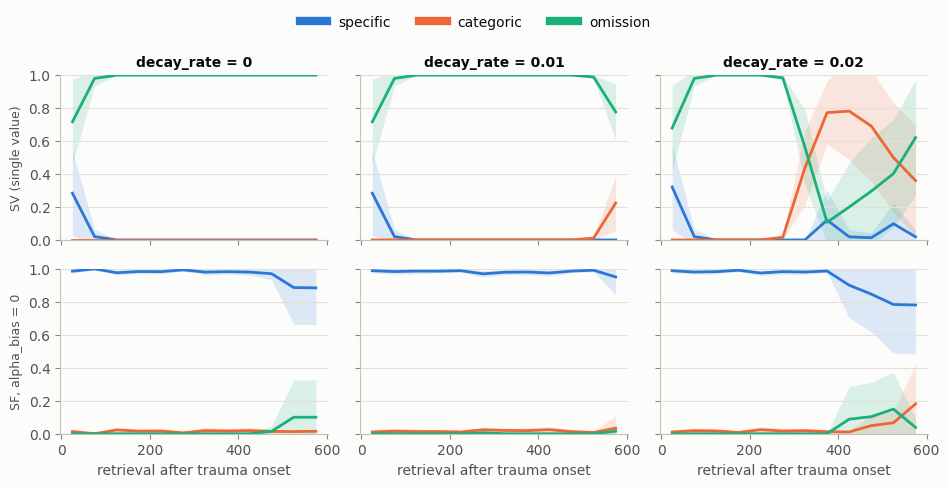

In [4]:
BLOCK = 50
tc = main[main["cue"] == "other"].copy()
tc["block"] = (tc["trial"] - 1) // BLOCK * BLOCK + BLOCK / 2
keys = ["spectrum", "decay_rate", "block"]
ts = summarise(per_seed_props(tc, keys), keys)

decays = params["decay_rates"]
specs = list(MAIN_LABELS)
fig, axes = plt.subplots(len(specs), len(decays), figsize=(3.2 * len(decays), 2.4 * len(specs)),
                         sharex=True, sharey=True)
for r, spec in enumerate(specs):
    for c, d in enumerate(decays):
        ax = axes[r, c]
        sub = ts[(ts["spectrum"] == spec) & (ts["decay_rate"] == d)]
        for o in OUTCOMES:
            s = sub[sub["outcome"] == o]
            ax.plot(s["block"], s["mean"], color=OUTCOME_COLORS[o])
            ax.fill_between(s["block"], s["mean"] - s["ci"], s["mean"] + s["ci"],
                            color=OUTCOME_COLORS[o], alpha=0.15, lw=0)
        if r == 0:
            ax.set_title(f"decay_rate = {d:g}")
        if c == 0:
            ax.set_ylabel(MAIN_LABELS[spec], fontsize=9)
        if r == len(specs) - 1:
            ax.set_xlabel("retrieval after trauma onset")
axes[0, 0].set_ylim(0, 1)
outcome_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

Averaged over the whole measured phase, one value per seed:

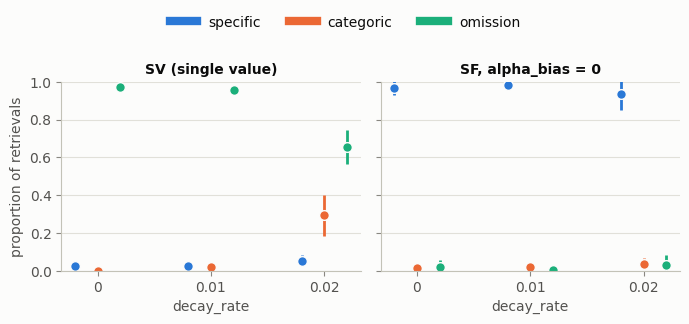

outcome                           specific    categoric     omission
spectrum           decay_rate                                       
SF, alpha_bias = 0 0.00        0.97 ± 0.04  0.01 ± 0.00  0.02 ± 0.04
                   0.01        0.98 ± 0.01  0.02 ± 0.01  0.00 ± 0.00
                   0.02        0.93 ± 0.08  0.04 ± 0.03  0.03 ± 0.05
SV (single value)  0.00        0.03 ± 0.02  0.00 ± 0.00  0.97 ± 0.02
                   0.01        0.03 ± 0.02  0.02 ± 0.01  0.96 ± 0.02
                   0.02        0.05 ± 0.03  0.29 ± 0.11  0.65 ± 0.09

In [5]:
keys = ["spectrum", "decay_rate"]
ms = summarise(per_seed_props(main[main["cue"] == "other"], keys), keys)

fig, axes = plt.subplots(1, len(MAIN_LABELS), figsize=(7, 3.2), sharey=True)
x = np.arange(len(decays))
offsets = dict(zip(OUTCOMES, (-0.2, 0, 0.2)))
for ax, spec in zip(axes, MAIN_LABELS):
    for o in OUTCOMES:
        s = ms[(ms["spectrum"] == spec) & (ms["outcome"] == o)].set_index("decay_rate").loc[decays]
        ax.errorbar(x + offsets[o], s["mean"], yerr=s["ci"], fmt="o", color=OUTCOME_COLORS[o],
                    ecolor=OUTCOME_COLORS[o], elinewidth=2, capsize=0, markeredgecolor="#fcfcfb")
    ax.set_title(MAIN_LABELS[spec])
    ax.set_xticks(x, [f"{d:g}" for d in decays])
    ax.set_xlabel("decay_rate")
axes[0].set_ylabel("proportion of retrievals")
axes[0].set_ylim(0, 1)
outcome_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

display(outcome_table(ms.assign(spectrum=ms["spectrum"].map(MAIN_LABELS)), ["spectrum", "decay_rate"]))

### Where the blame lands

`w_bias` is the weight on retrieval-in-general (for SV, its single value); `w_trauma` is the mean weight on the trauma group's own features (SF only). Localisation means `w_trauma` stays negative while `w_bias` recovers.

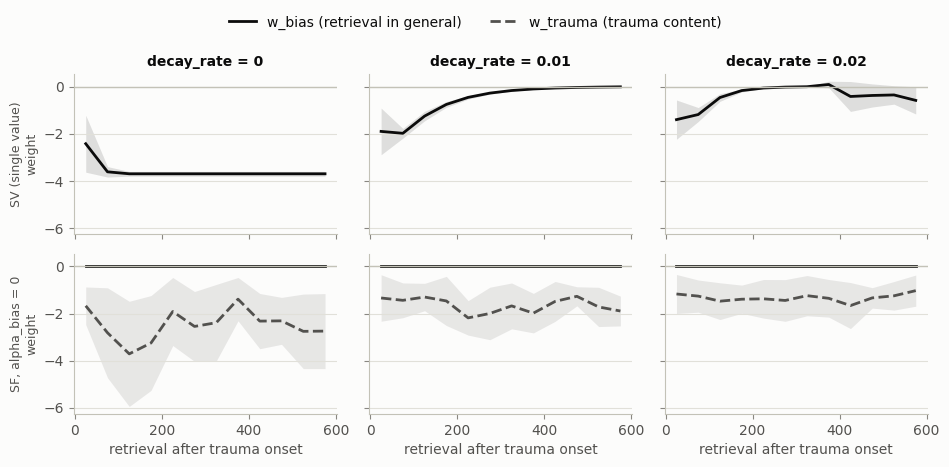

In [6]:
wt = main.copy()
wt["block"] = (wt["trial"] - 1) // BLOCK * BLOCK + BLOCK / 2
per_seed_w = wt.groupby(["spectrum", "decay_rate", "block", "seed"])[["w_bias", "w_trauma"]].mean().reset_index()

def mean_ci(s):
    n = s.count()
    half = stats.t.ppf(0.975, max(n - 1, 1)) * s.std() / np.sqrt(n) if n > 1 else 0.0
    return pd.Series({"mean": s.mean(), "ci": half})

fig, axes = plt.subplots(2, len(decays), figsize=(3.2 * len(decays), 4.6), sharex=True, sharey=True)
styles = {"w_bias": dict(color=INK, ls="-", label="w_bias (retrieval in general)"),
          "w_trauma": dict(color=INK_2, ls="--", label="w_trauma (trauma content)")}
for r, spec in enumerate(MAIN_LABELS):
    for c, d in enumerate(decays):
        ax = axes[r, c]
        sub = per_seed_w[(per_seed_w["spectrum"] == spec) & (per_seed_w["decay_rate"] == d)]
        for col, st in styles.items():
            if sub[col].isna().all():
                continue
            s = sub.groupby("block")[col].apply(mean_ci).unstack()
            ax.plot(s.index, s["mean"], **st)
            ax.fill_between(s.index, s["mean"] - s["ci"], s["mean"] + s["ci"], color=st["color"], alpha=0.12, lw=0)
        ax.axhline(0, color=AXIS, lw=1)
        if r == 0:
            ax.set_title(f"decay_rate = {d:g}")
        if c == 0:
            ax.set_ylabel(f"{MAIN_LABELS[spec]}\nweight", fontsize=9)
        if r == 1:
            ax.set_xlabel("retrieval after trauma onset")
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 3. Sensitivity: where SF stops localising

SF across `alpha_bias` (with SV as the pole) at `decay_rate = 0.01`, measured phase averaged per seed. If SF's advantage depends on a pure content code, specific retrieval on *other* cues should fall as `alpha_bias` grows.

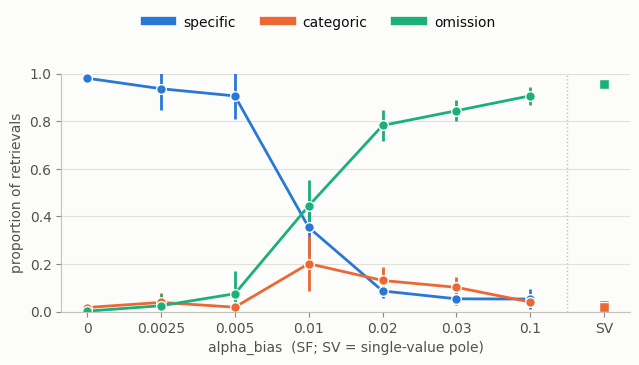

outcome,specific,categoric,omission
spectrum,,,
SF 0,0.98 ± 0.01,0.02 ± 0.01,0.00 ± 0.00
SF 0.0025,0.94 ± 0.09,0.04 ± 0.04,0.02 ± 0.05
SF 0.005,0.91 ± 0.10,0.02 ± 0.01,0.08 ± 0.10
SF 0.01,0.35 ± 0.12,0.20 ± 0.11,0.44 ± 0.11
SF 0.02,0.09 ± 0.03,0.13 ± 0.06,0.78 ± 0.06
SF 0.03,0.05 ± 0.02,0.10 ± 0.04,0.84 ± 0.04
SF 0.1,0.05 ± 0.04,0.04 ± 0.02,0.91 ± 0.04
SV,0.03 ± 0.02,0.02 ± 0.01,0.96 ± 0.02


In [7]:
order = [f"SF {a:g}" for a in params["alpha_bias_values"]] + ["SV"]
order = [o for o in order if o in set(sens["spectrum"])]
ss = summarise(per_seed_props(sens[sens["cue"] == "other"], ["spectrum"]), ["spectrum"])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(order))
sf = [i for i, lab in enumerate(order) if lab != "SV"]
for o in OUTCOMES:
    s = ss[ss["outcome"] == o].set_index("spectrum").loc[order]
    # SF points are joined along the spectrum; SV is the pole, drawn apart.
    ax.errorbar(x[sf], s["mean"].iloc[sf], yerr=s["ci"].iloc[sf], color=OUTCOME_COLORS[o],
                marker="o", elinewidth=2, capsize=0, markeredgecolor="#fcfcfb")
    if "SV" in order:
        ax.errorbar(x[-1:], s["mean"].iloc[-1:], yerr=s["ci"].iloc[-1:], color=OUTCOME_COLORS[o],
                    fmt="s", elinewidth=2, capsize=0, markeredgecolor="#fcfcfb")
if "SV" in order:
    ax.axvline(len(order) - 1.5, color=AXIS, lw=1, ls=":")
ax.set_xticks(x, [o.replace("SF ", "") for o in order])
ax.set_xlabel("alpha_bias  (SF; SV = single-value pole)")
ax.set_ylabel("proportion of retrievals")
ax.set_ylim(0, 1)
outcome_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

display(outcome_table(ss, "spectrum").reindex(order))

## 4. Severity sweep: categoric memories or omissions?

In AMT data, overgeneral retrieval shows up mostly as **categoric** memories, with relatively few omissions. Here the trauma's severity (valence) is crossed with the payoff of giving a categoric answer (`summary_report`; a specific answer pays `event_report` = 0.5), at `decay_rate = 0.01`, for the SV pole, SF at `alpha_bias = 0`, and SF at the transition (`alpha_bias = 0.01`). A categoric answer becomes the agent's way out when searching on looks worse than reporting the general memory, but not worse than reporting nothing — so milder trauma and more acceptable general answers should widen that band.

**Read with section 5:** these are averages over the whole 600-retrieval measured phase. The time course shows that more severe trauma mainly *delays* the switch from omissions to categoric answers, so the drop in categoric answers at −20 and −50 largely reflects the window ending before those runs settle.

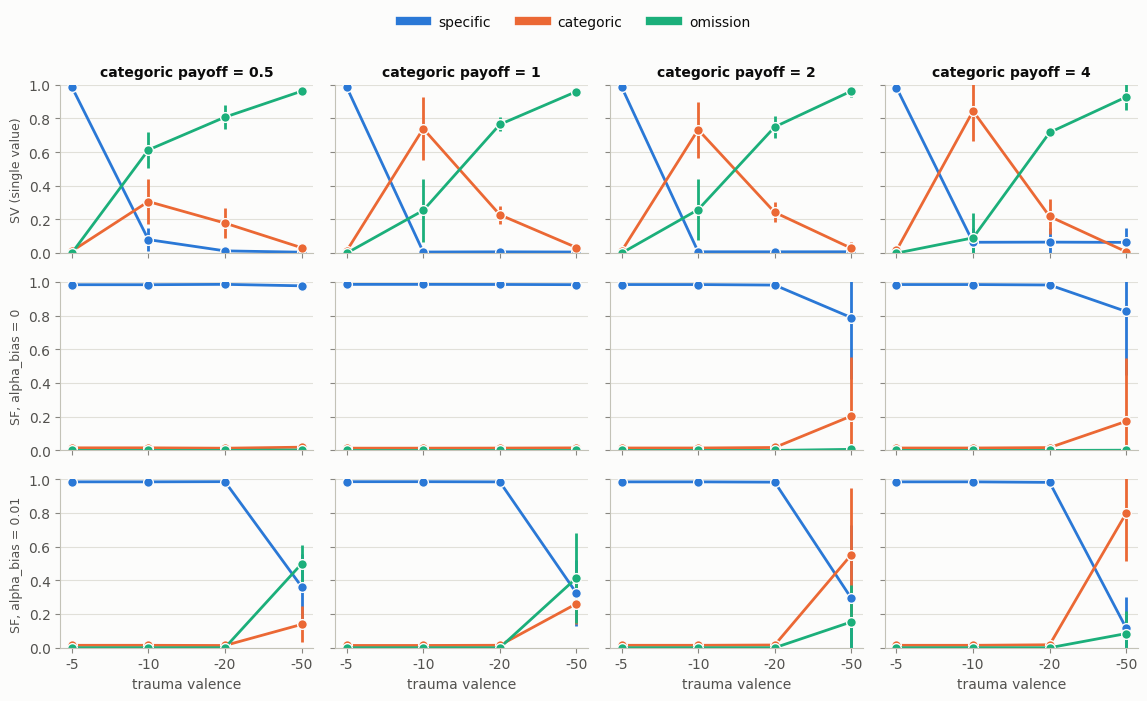

In [8]:
SEV_SPECS = [f"SV" if a == "SV" else f"SF {ab:g}" for a, ab in params["severity_agents"]]
SEV_LABELS = {"SV": "SV (single value)", "SF 0": "SF, alpha_bias = 0", "SF 0.01": "SF, alpha_bias = 0.01"}
sev = measured[(measured["decay_rate"] == params["sens_decay"]) & measured["spectrum"].isin(SEV_SPECS)
               & (measured["seed"] < params["severity_seeds"])]
valences = sorted(params["severity_valences"], reverse=True)       # mild -> severe
reports = params["severity_summary_reports"]
keys = ["spectrum", "summary_report", "trauma_valence"]
sv = summarise(per_seed_props(sev[sev["cue"] == "other"], keys), keys)

def severity_grid():
    fig, axes = plt.subplots(len(SEV_SPECS), len(reports), figsize=(2.9 * len(reports), 2.3 * len(SEV_SPECS)),
                             sharex=True, sharey=True)
    x = np.arange(len(valences))
    for r, spec in enumerate(SEV_SPECS):
        for c, rep in enumerate(reports):
            ax = axes[r, c]
            sub = sv[(sv["spectrum"] == spec) & (sv["summary_report"] == rep)]
            for o in OUTCOMES:
                s = sub[sub["outcome"] == o].set_index("trauma_valence").reindex(valences)
                ax.errorbar(x, s["mean"], yerr=s["ci"], color=OUTCOME_COLORS[o], marker="o",
                            elinewidth=2, capsize=0, markeredgecolor="#fcfcfb")
            if r == 0:
                ax.set_title(f"categoric payoff = {rep:g}")
            if c == 0:
                ax.set_ylabel(SEV_LABELS[spec], fontsize=9)
            if r == len(SEV_SPECS) - 1:
                ax.set_xticks(x, [f"{v:g}" for v in valences])
                ax.set_xlabel("trauma valence")
    axes[0, 0].set_ylim(0, 1)
    outcome_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

severity_grid()

Table (mean ± 95% CI across seeds):

In [9]:
display(outcome_table(sv.assign(spectrum=sv["spectrum"].map(SEV_LABELS)),
                     ["spectrum", "summary_report", "trauma_valence"]))

outcome                                                 specific    categoric  \
spectrum              summary_report trauma_valence                             
SF, alpha_bias = 0    0.5            -50             0.98 ± 0.03  0.02 ± 0.02   
                                     -20             0.99 ± 0.01  0.01 ± 0.01   
                                     -10             0.98 ± 0.00  0.02 ± 0.00   
                                     -5              0.98 ± 0.00  0.02 ± 0.00   
                      1.0            -50             0.98 ± 0.01  0.02 ± 0.01   
                                     -20             0.99 ± 0.01  0.01 ± 0.01   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
                      2.0            -50             0.79 ± 0.36  0.20 ± 0.35   
                                     -20             0.98 ± 0.00  0.02 ± 0.00   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
                      4.0            -50             0.83 ± 0.38  0.17 ± 0.38   
                                     -20             0.98 ± 0.00  0.02 ± 0.00   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
SF, alpha_bias = 0.01 0.5            -50             0.36 ± 0.19  0.14 ± 0.11   
                                     -20             0.99 ± 0.01  0.01 ± 0.01   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
                      1.0            -50             0.32 ± 0.20  0.26 ± 0.12   
                                     -20             0.99 ± 0.00  0.01 ± 0.00   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
                      2.0            -50             0.29 ± 0.44  0.55 ± 0.40   
                                     -20             0.98 ± 0.00  0.02 ± 0.00   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
                      4.0            -50             0.12 ± 0.19  0.80 ± 0.28   
                                     -20             0.98 ± 0.01  0.02 ± 0.01   
                                     -10             0.99 ± 0.00  0.01 ± 0.00   
                                     -5              0.99 ± 0.00  0.01 ± 0.00   
SV (single value)     0.5            -50             0.01 ± 0.01  0.03 ± 0.02   
                                     -20             0.01 ± 0.02  0.18 ± 0.09   
                                     -10             0.08 ± 0.07  0.31 ± 0.13   
                                     -5              0.99 ± 0.01  0.01 ± 0.01   
                      1.0            -50             0.01 ± 0.01  0.03 ± 0.02   
                                     -20             0.01 ± 0.02  0.23 ± 0.05   
                                     -10             0.01 ± 0.01  0.74 ± 0.19   
                                     -5              0.99 ± 0.01  0.01 ± 0.01   
                      2.0            -50             0.01 ± 0.01  0.03 ± 0.04   
                                     -20             0.01 ± 0.01  0.24 ± 0.06   
                                     -10             0.01 ± 0.01  0.73 ± 0.17   
                                     -5              0.99 ± 0.01  0.01 ± 0.01   
                      4.0            -50             0.06 ± 0.08  0.01 ± 0.01   
                                     -20             0.07 ± 0.09  0.22 ± 0.10   
                                     -10             0.06 ± 0.08  0.84 ± 0.18   
                               

## 5. The spectrum: content share

One parameter places an agent on the spectrum. `content_share` splits the total reward-learning rate (`alpha_w`) between memory **content** and the **bias** feature ("retrieval in general"): `alpha_content = content_share × alpha_w`, `alpha_bias = (1 − content_share) × alpha_w`. At 1 all blame for the trauma stays with what the memory is about; at 0 (the pole) only retrieval in general carries value. The pole is not the SV agent of sections 2–4: both learn value the same way, but at share 0 the successor features still tell memories apart, so the agent can still expect different search lengths and endings from different groups.

Settings: moderate trauma (valence = `spectrum_valence`), categoric payoff = `spectrum_summary_report`, `decay_rate` = `sens_decay`, and a long measured phase (`spectrum_measured` retrievals) so slow agents can settle. Lines are means across seeds, bands 95% CIs, in blocks of 50 retrievals.

*Sections 2–4 predate the merged axis: they vary `alpha_bias` with content learning at `alpha_w` (so their total rate grows with `alpha_bias`); `alpha_bias = 0` there is `content_share = 1` here.*

valence -10, categoric payoff 1, decay 0.01; seeds: 1 10, 0.75 10, 0.5 10, 0.3 10, 0.2 10, 0.1 10, 0.05 10, 0 10


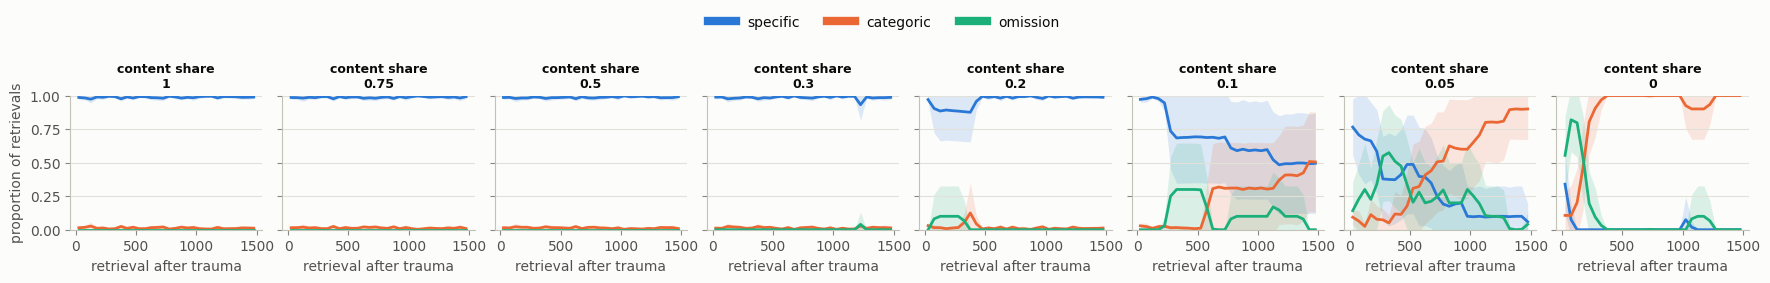

In [10]:
BLOCK_SP = 50
SHARES = sorted(params["content_shares"], reverse=True)              # content-specific -> pole
SP_SPECS = [f"{c:g}" for c in SHARES]

spd = trials[(trials["phase"] == "measured") & (trials["run_length"] == params["spectrum_measured"])
             & trials["on_spectrum"] & (trials["agent"] == "SF")
             & (trials["trauma_valence"] == params["spectrum_valence"])
             & (trials["summary_report"] == params["spectrum_summary_report"])
             & (trials["decay_rate"] == params["sens_decay"])].copy()
# label = content share, so the helpers group by it
spd["spectrum"] = spd["content_share"].map(lambda c: f"{c:g}")
spd = spd[spd["spectrum"].isin(SP_SPECS) & (spd["cue"] == "other")]
spd["block"] = (spd["trial"] - 1) // BLOCK_SP * BLOCK_SP + BLOCK_SP / 2
print(f"valence {params['spectrum_valence']}, categoric payoff {params['spectrum_summary_report']}, "
      f"decay {params['sens_decay']}; seeds: "
      + ", ".join(f"{k} {v}" for k, v in spd.groupby("spectrum").seed.nunique().reindex(SP_SPECS).items()))


def share_label(spec):
    return f"content share = {spec}"


def timecourse_row(d, specs, label):
    """Outcome shares over time, one panel per agent."""
    keys = ["spectrum", "block"]
    s_all = summarise(per_seed_props(d, keys), keys)
    fig, axes = plt.subplots(1, len(specs), figsize=(2.2 * len(specs), 2.8), sharex=True, sharey=True)
    for ax, spec in zip(axes, specs):
        sub = s_all[s_all["spectrum"] == spec]
        for o in OUTCOMES:
            s = sub[sub["outcome"] == o]
            ax.plot(s["block"], s["mean"], color=OUTCOME_COLORS[o])
            ax.fill_between(s["block"], s["mean"] - s["ci"], s["mean"] + s["ci"],
                            color=OUTCOME_COLORS[o], alpha=0.15, lw=0)
        ax.set_title(label(spec).replace(" = ", "\n"), fontsize=9)
        ax.set_xlabel("retrieval after trauma")
    axes[0].set_ylabel("proportion of retrievals")
    axes[0].set_ylim(0, 1)
    outcome_legend(fig)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()


timecourse_row(spd, SP_SPECS, share_label)

**Where each agent settles.** Steady state is the outcome mix over the last 200 retrievals (mean ± 95% CI; points joined along the share). Onset is, per seed, the first 50-retrieval block in which categoric answers are more than half of the retrievals; the table gives the median over the seeds that got there and how many did. Because single runs tend to lock into one habit, the last table counts seeds by their end state (≥ 80% of the last 200 retrievals of one kind, otherwise *mixed*).

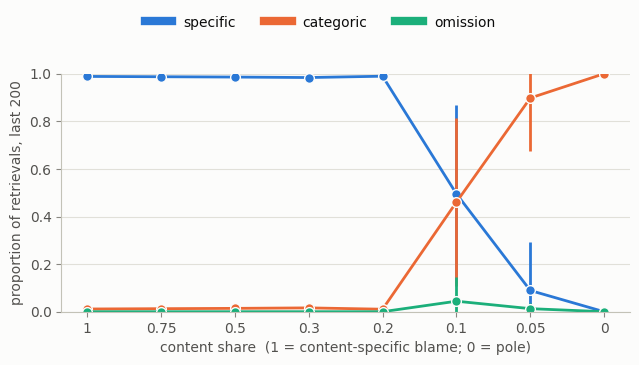

outcome,specific,categoric,omission
"content share, last 200",,,
1,0.99 ± 0.01,0.01 ± 0.01,0.00 ± 0.00
0.75,0.99 ± 0.01,0.01 ± 0.01,0.00 ± 0.00
0.5,0.99 ± 0.01,0.01 ± 0.01,0.00 ± 0.00
0.3,0.98 ± 0.01,0.02 ± 0.01,0.00 ± 0.00
0.2,0.99 ± 0.01,0.01 ± 0.01,0.00 ± 0.00
0.1,0.50 ± 0.37,0.46 ± 0.35,0.04 ± 0.10
0.05,0.09 ± 0.20,0.90 ± 0.22,0.01 ± 0.02
0,0.00 ± 0.00,1.00 ± 0.00,0.00 ± 0.00


,median onset (retrieval),seeds reaching onset,ends specific,ends categoric,ends omission,ends mixed
content share,,,,,,
1,NaN,0 / 10,10,0,0,0
0.75,NaN,0 / 10,10,0,0,0
0.5,NaN,0 / 10,10,0,0,0
0.3,NaN,0 / 10,10,0,0,0
0.2,351.0,1 / 10,10,0,0,0
0.1,601.0,5 / 10,5,4,0,1
0.05,651.0,10 / 10,1,9,0,0
0,201.0,10 / 10,0,10,0,0


In [11]:
last = spd[spd["trial"] > params["spectrum_measured"] - 200]
whole = per_seed_props(last, ["spectrum"])
ss = summarise(whole, ["spectrum"])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(SP_SPECS))
for o in OUTCOMES:
    s = ss[ss["outcome"] == o].set_index("spectrum").reindex(SP_SPECS)
    ax.errorbar(x, s["mean"], yerr=s["ci"], color=OUTCOME_COLORS[o],
                marker="o", elinewidth=2, capsize=0, markeredgecolor="#fcfcfb")
ax.set_xticks(x, SP_SPECS)
ax.set_xlabel("content share  (1 = content-specific blame; 0 = pole)")
ax.set_ylabel("proportion of retrievals, last 200")
ax.set_ylim(0, 1)
outcome_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

display(outcome_table(ss, "spectrum").reindex(SP_SPECS).rename_axis("content share, last 200"))

blk = (spd.groupby(["spectrum", "seed", "block"])["outcome"]
       .apply(lambda o: (o == "categoric").mean()).reset_index(name="categoric"))
first = blk[blk["categoric"] > 0.5].groupby(["spectrum", "seed"])["block"].min() - BLOCK_SP / 2 + 1
n_seeds = spd.groupby("spectrum").seed.nunique()

whole = whole.set_index(["spectrum", "seed"])[OUTCOMES]
end_state = whole.idxmax(axis=1).where(whole.max(axis=1) >= 0.8, "mixed")
counts = end_state.groupby("spectrum").value_counts().unstack(fill_value=0)
counts = counts.reindex(columns=OUTCOMES + ["mixed"], fill_value=0)

display(pd.DataFrame({
    "median onset (retrieval)": first.groupby("spectrum").median(),
    "seeds reaching onset": first.groupby("spectrum").size().reindex(n_seeds.index, fill_value=0).astype(str)
                            + " / " + n_seeds.astype(str),
}).join(counts.add_prefix("ends ")).reindex(SP_SPECS).rename_axis("content share"))

**Weights.** `w_bias` (retrieval in general) and `w_trauma` (mean weight of the trauma group's own features). Flat stretches during omission phases are expected: omissions teach nothing, so only decay moves the weights.

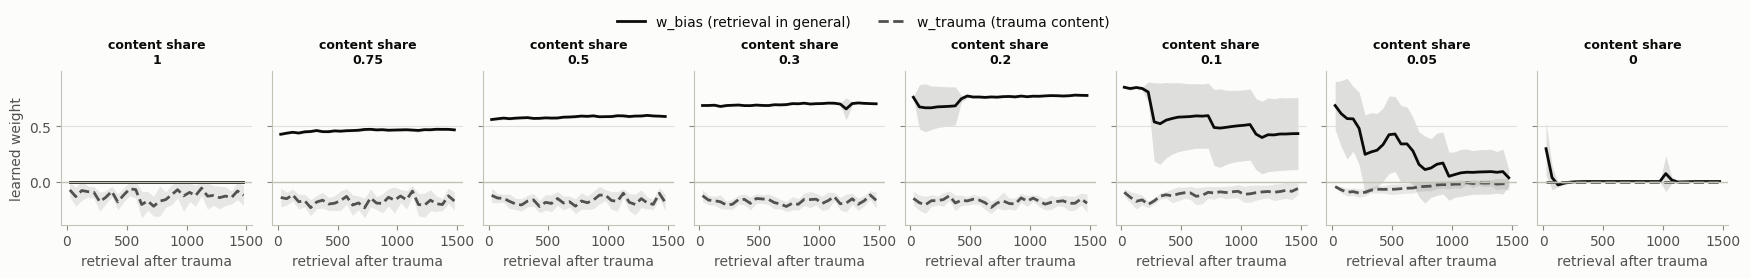

In [12]:
per_seed_w = spd.groupby(["spectrum", "block", "seed"])[["w_bias", "w_trauma"]].mean().reset_index()
fig, axes = plt.subplots(1, len(SP_SPECS), figsize=(2.2 * len(SP_SPECS), 2.6), sharex=True, sharey=True)
for ax, spec in zip(axes, SP_SPECS):
    sub = per_seed_w[per_seed_w["spectrum"] == spec]
    for col, st in styles.items():
        if sub[col].isna().all():
            continue
        s = sub.groupby("block")[col].apply(mean_ci).unstack()
        ax.plot(s.index, s["mean"], **st)
        ax.fill_between(s.index, s["mean"] - s["ci"], s["mean"] + s["ci"], color=st["color"], alpha=0.12, lw=0)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_title(share_label(spec).replace(" = ", "\n"), fontsize=9)
    ax.set_xlabel("retrieval after trauma")
axes[0].set_ylabel("learned weight")
handles = [plt.Line2D([], [], **st) for st in styles.values()]
fig.legend(handles, [st["label"] for st in styles.values()], ncol=2, loc="upper center",
           bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
plt.show()

## 6. Check: trauma reminders vs other cues

Every condition from sections 2–5, measured phase pooled. For each seed, the outcome proportion on trauma cues minus that on other cues; the figure plots the mean difference per condition (0 = the trauma reminder is answered like any other cue). A positive omission difference with a negative specific one is **localised avoidance**: the agent avoids the trauma's own memories while answering other cues normally. Points are split by trauma valence.

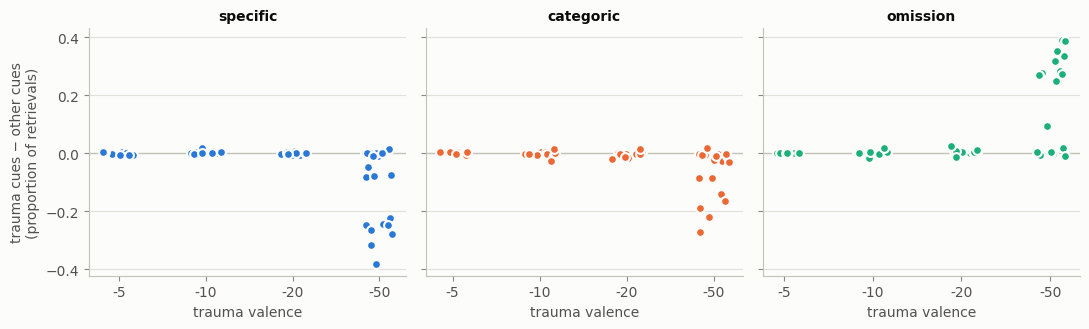

13 of 65 conditions differ by more than 0.05 on some outcome:


,specific,categoric,omission
valence | condition (trauma − other),,,
"-50 | SF ab 0 / ac 0.1, decay 0, payoff 0.5, n 600",-0.38 ± 0.13,-0.01 ± 0.01,+0.39 ± 0.13
"-50 | SF ab 0 / ac 0.1, decay 0.01, payoff 0.5, n 600",-0.28 ± 0.05,-0.00 ± 0.01,+0.28 ± 0.05
"-50 | SF ab 0 / ac 0.1, decay 0.01, payoff 1, n 600",-0.32 ± 0.09,-0.00 ± 0.01,+0.32 ± 0.09
"-50 | SF ab 0 / ac 0.1, decay 0.01, payoff 2, n 600",-0.24 ± 0.12,-0.14 ± 0.23,+0.39 ± 0.16
"-50 | SF ab 0 / ac 0.1, decay 0.01, payoff 4, n 600",-0.25 ± 0.16,-0.09 ± 0.16,+0.33 ± 0.10
"-50 | SF ab 0 / ac 0.1, decay 0.02, payoff 0.5, n 600",-0.23 ± 0.06,-0.03 ± 0.03,+0.25 ± 0.05
"-50 | SF ab 0.0025 / ac 0.1, decay 0.01, payoff 0.5, n 600",-0.25 ± 0.07,-0.02 ± 0.04,+0.27 ± 0.06
"-50 | SF ab 0.005 / ac 0.1, decay 0.01, payoff 0.5, n 600",-0.27 ± 0.06,-0.01 ± 0.01,+0.28 ± 0.06
"-50 | SF ab 0.01 / ac 0.1, decay 0.01, payoff 0.5, n 600",-0.08 ± 0.05,-0.19 ± 0.11,+0.27 ± 0.09


In [13]:
COND = ["agent", "alpha_bias", "alpha_content", "decay_rate", "trauma_valence", "summary_report", "run_length"]
allm = trials[trials["phase"] == "measured"].copy()
allm["alpha_bias"] = allm["alpha_bias"].fillna(-1)          # SV has none; keep it groupable
by_cue = per_seed_props(allm, COND + ["cue"]).set_index(COND + ["seed", "cue"])[OUTCOMES].unstack("cue")
diff = pd.concat({o: by_cue[(o, "trauma")] - by_cue[(o, "other")] for o in OUTCOMES}, axis=1).dropna()
cond_diff = diff.groupby(COND).agg(["mean", lambda s: mean_ci(s)["ci"]])
cond_diff.columns = [f"{o} {'mean' if k == 'mean' else 'ci'}" for o, k in cond_diff.columns]
cond_diff = cond_diff.reset_index()


def cond_label(r):
    who = "SV" if r["agent"] == "SV" else f"SF ab {r['alpha_bias']:g} / ac {r['alpha_content']:g}"
    return f"{who}, decay {r['decay_rate']:g}, payoff {r['summary_report']:g}, n {r['run_length']}"


cond_diff["condition"] = cond_diff.apply(cond_label, axis=1)
vals = sorted(cond_diff["trauma_valence"].unique(), reverse=True)

fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(11, 3.4), sharey=True)
rng = np.random.default_rng(0)
for ax, o in zip(axes, OUTCOMES):
    for k, v in enumerate(vals):
        s = cond_diff[cond_diff["trauma_valence"] == v]
        ax.scatter(k + rng.uniform(-0.18, 0.18, len(s)), s[f"{o} mean"], s=40, color=OUTCOME_COLORS[o],
                   edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_xticks(range(len(vals)), [f"{v:g}" for v in vals])
    ax.set_xlabel("trauma valence")
    ax.set_title(o)
axes[0].set_ylabel("trauma cues − other cues\n(proportion of retrievals)")
fig.tight_layout()
plt.show()

big = cond_diff[cond_diff[[f"{o} mean" for o in OUTCOMES]].abs().max(axis=1) > 0.05]
print(f"{len(big)} of {len(cond_diff)} conditions differ by more than 0.05 on some outcome:")
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame({o: big[f"{o} mean"].map("{:+.2f}".format) + " ± " + big[f"{o} ci"].map("{:.2f}".format)
                      for o in OUTCOMES}).set_axis(big["trauma_valence"].astype(int).astype(str) + " | " + big["condition"])
        .rename_axis("valence | condition (trauma − other)"))

## 7. The network across the transition

A few spectrum runs (content share 0.2, 0.1 and 0.05; at 0.1 one seed that stays specific and one that switches to categoric answers) were re-run with the same seed by `python experiments.py --snapshots` and inspected at several points in the measured phase. These are single runs, chosen to be typical of their share, not averages.

**Where the agent would stop.** Each cluster is one group of memories: the **cue** (square, top), the group's **summary** node (centre) and its 20 **events** (ring). Colour is the agent's **advantage of continuing** at that point: the learned value of searching on minus the payoff of stopping there. Stopping at the cue is an omission (payoff 0), at the summary a categoric answer (`spectrum_summary_report`), at an event a specific answer (`event_report`). Purple means the agent keeps searching, brown that it stops. With `temp` = 0.1 the choice is close to all-or-none: an advantage beyond about ±0.5 means it (almost) always continues or always stops. The trauma memory is the large ringed event at the bottom of its group. The network grows by one 20-memory group after every retrieval (155 groups before the trauma, about 1,550 by the last snapshot), so the clusters are a fixed sample: the trauma group, three groups learned before the trauma, and the newest group (just added, never retrieved: how the agent treats unfamiliar content). The figure after the table covers every group.

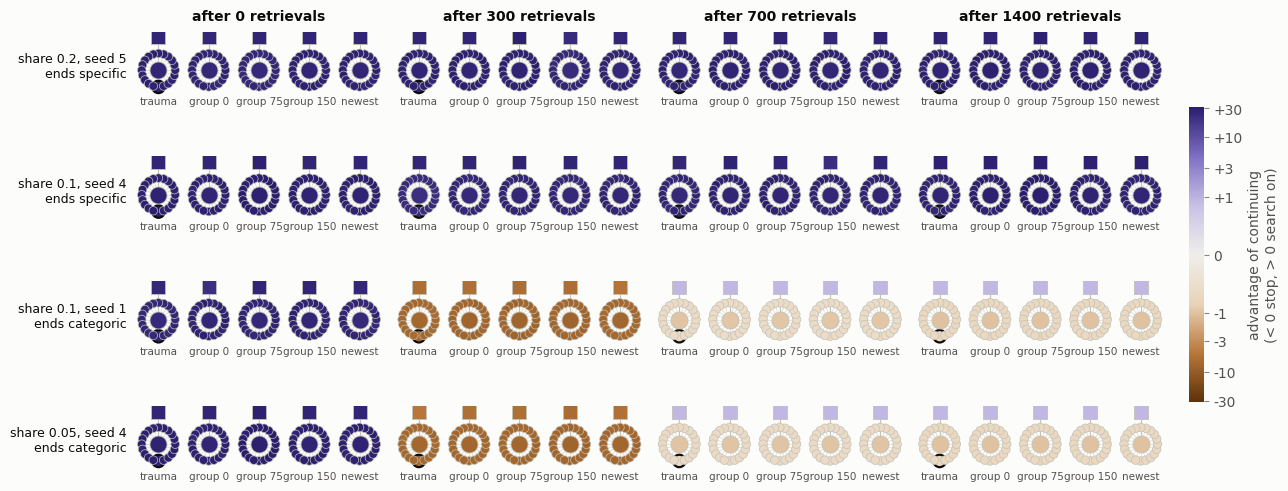

Learned weights, and the advantage of continuing at the trauma and newest groups (events averaged):


w_bias  w_categoric  w_specific  \
run                                after                                    
share 0.2, seed 5, ends specific   0        0.77         0.21        0.45   
                                   300      0.73         0.04        0.45   
                                   700      0.77         0.17        0.45   
                                   1400     0.78         0.20        0.45   
share 0.1, seed 4, ends specific   0        0.89         0.31        0.45   
                                   300      0.86         0.13        0.45   
                                   700      0.84         0.16        0.45   
                                   1400     0.88         0.03        0.45   
share 0.1, seed 1, ends categoric  0        0.84         0.21        0.45   
                                   300     -0.31         0.09        0.31   
                                   700      0.00         0.91        0.01   
                                   1400     0.00         0.91        0.00   
share 0.05, seed 4, ends categoric 0        0.94         0.31        0.45   
                                   300     -0.27         0.09        0.31   
                                   700      0.00         0.91        0.01   
                                   1400     0.00         0.91        0.00   

                                          trauma: cue  trauma: summary  \
run                                after                                 
share 0.2, seed 5, ends specific   0            26.30            26.16   
                                   300          26.28            26.06   
                                   700          26.60            25.61   
                                   1400         27.97            27.22   
share 0.1, seed 4, ends specific   0            25.95            27.33   
                                   300          24.55            20.68   
                                   700          25.35            23.79   
                                   1400         28.23            25.98   
share 0.1, seed 1, ends categoric  0            24.94            24.10   
                                   300          -5.92            -7.23   
                                   700           0.90            -0.96   
                                   1400          0.90            -1.01   
share 0.05, seed 4, ends categoric 0            25.96            27.29   
                                   300          -4.90            -7.36   
                                   700           0.90            -0.97   
                                   1400          0.90            -1.01   

                                          trauma: event  newest: cue  \
run                                after                               
share 0.2, seed 5, ends specific   0              28.33        26.30   
                                   300            28.31        25.49   
                                   700            27.66        26.93   
                                   1400           28.45        27.75   
share 0.1, seed 4, ends specific   0              29.34        25.95   
                                   300            22.27        26.14   
                                   700            25.55        26.32   
                                   1400           26.99        28.02   
share 0.1, seed 1, ends categoric  0              25.18        24.94   
                                   300            -6.95        -5.32   
                                   700            -0.46         0.90   
                                   1400           -0.51         0.90   
share 0.05, seed 4, ends categoric 0              29.30        25.96   
                                   300            -7.11        -5.59   
                                   700            -0.47         0.90   
                                   1400           -0.51         0.90   

                         

In [14]:
import matplotlib.colors as mcolors

with open(os.path.join(DATA_DIR, "network", "snapshots.json")) as f:
    snap = json.load(f)
# Diverging: brown = stop, neutral grey at 0 (indifferent), purple = keep searching.
ADV_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "advantage", ["#5c3209", "#b9773a", "#e9d3b8", "#efeeea", "#c9c1e6", "#7f6fc4", "#2a1d6e"])
# Symmetric log scale: margins of about ±1 (where the categoric habit lives) stay visible next to values of ~30.
ADV_NORM = mcolors.SymLogNorm(linthresh=0.5, linscale=0.6, vmin=-32, vmax=32, base=10)
REPORT = {"event": params["event_report"], "summary": params["spectrum_summary_report"]}


def adv(n):
    """Advantage of continuing at a node: value of searching on - payoff of reporting it."""
    return n["q"] - REPORT[n["level"]]


def col(v):
    return ADV_CMAP(ADV_NORM(np.clip(v, -32, 32)))


def run_label(r):
    last = r["outcomes"][-200:]
    shares = {o: last.count(o) / len(last) for o in OUTCOMES}
    end = max(shares, key=shares.get) if max(shares.values()) >= 0.8 else "mixed"
    return f"share {r['content_share']:g}, seed {r['seed']}\nends {end}"


def group_name(g, s):
    if g == s["trauma_group"]:
        return "trauma"
    if g == s["newest_group"]:
        return "newest"
    return f"group {g}"


def draw_cluster(ax, x0, grp, label):
    events = [n for n in grp["nodes"] if n["level"] == "event"]
    summ = [n for n in grp["nodes"] if n["level"] == "summary"][0]
    ang = np.linspace(0, 2 * np.pi, len(events), endpoint=False) - np.pi / 2   # first event (the trauma memory, in its group) at the bottom
    ex, ey = x0 + np.cos(ang), np.sin(ang)
    for x, y in zip(ex, ey):                                  # summary -> event links
        ax.plot([x0, x], [0, y], color=GRID, lw=0.6, zorder=1)
    ax.plot([x0, x0], [0, 1.75], color=AXIS, lw=0.8, zorder=1)   # cue -> summary
    ax.scatter(ex, ey, s=[80 if n["trauma"] else 38 for n in events], c=[col(adv(n)) for n in events],
               edgecolors=[INK if n["trauma"] else AXIS for n in events],
               linewidths=[1.6 if n["trauma"] else 0.5 for n in events], zorder=3)
    ax.scatter([x0], [0], s=150, c=[col(adv(summ))], edgecolors=AXIS, linewidths=0.6, zorder=3)
    ax.scatter([x0], [1.95], s=110, marker="s", c=[col(grp["cue_q"])],
               edgecolors=AXIS, linewidths=0.6, zorder=3)
    ax.text(x0, -1.6, label, ha="center", va="top", fontsize=7.5, color=INK_2)


runs = snap["runs"]
times = [s["t"] for s in runs[0]["snapshots"]]
SP = 3.0
fig, axes = plt.subplots(len(runs), len(times), figsize=(4.0 * len(times), 1.6 * len(runs)))
fig.subplots_adjust(wspace=0.05, hspace=0.05)
for r, run in enumerate(runs):
    for c, s in enumerate(run["snapshots"]):
        ax = axes[r, c]
        for k, grp in enumerate(s["groups"]):
            draw_cluster(ax, k * SP, grp, group_name(grp["group"], s))
        ax.set_xlim(-1.4, (len(s["groups"]) - 1) * SP + 1.4)
        ax.set_ylim(-2.0, 2.3)
        ax.set_aspect("equal")
        ax.axis("off")
        if r == 0:
            ax.set_title(f"after {s['t']} retrievals", pad=8)
        if c == 0:
            ax.text(-1.9, 0.2, run_label(run), ha="right", va="center", fontsize=9, color=INK)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=ADV_NORM, cmap=ADV_CMAP), ax=axes, shrink=0.6, pad=0.02)
ADV_TICKS = [-30, -10, -3, -1, 0, 1, 3, 10, 30]
cb.set_ticks(ADV_TICKS, labels=[f"{t:+d}" if t else "0" for t in ADV_TICKS])
cb.ax.minorticks_off()
cb.set_label("advantage of continuing\n(< 0 stop, > 0 search on)")
cb.outline.set_visible(False)
plt.show()

rows = []
for run in runs:
    for s in run["snapshots"]:
        row = {"run": run_label(run).replace("\n", ", "), "after": s["t"], "w_bias": s["w_bias"],
               "w_categoric": s["w_cat"], "w_specific": s["w_spec"]}
        for g in s["groups"]:
            if g["group"] in (s["trauma_group"], s["newest_group"]):
                name = group_name(g["group"], s)
                row[f"{name}: cue"] = g["cue_q"]
                for lvl in ("summary", "event"):
                    row[f"{name}: {lvl}"] = np.mean([adv(n) for n in g["nodes"] if n["level"] == lvl])
        rows.append(row)
print("Learned weights, and the advantage of continuing at the trauma and newest groups (events averaged):")
display(pd.DataFrame(rows).set_index(["run", "after"]).round(2))

**Every group.** The same advantage of continuing for every group in the network at each snapshot, in the order the groups were created (left: the initial and warm-up groups; dotted line: the trauma group; right of it: groups added after the trauma, one per retrieval). Each group contributes three points, one per place the search could stop, coloured by the answer stopping there would give: the cue (omission), the summary node (categoric) and the mean over its events (specific). Above 0 the agent searches on from that point, below 0 it stops; the y-axis is symmetric-log, so it is linear between −0.5 and 0.5.

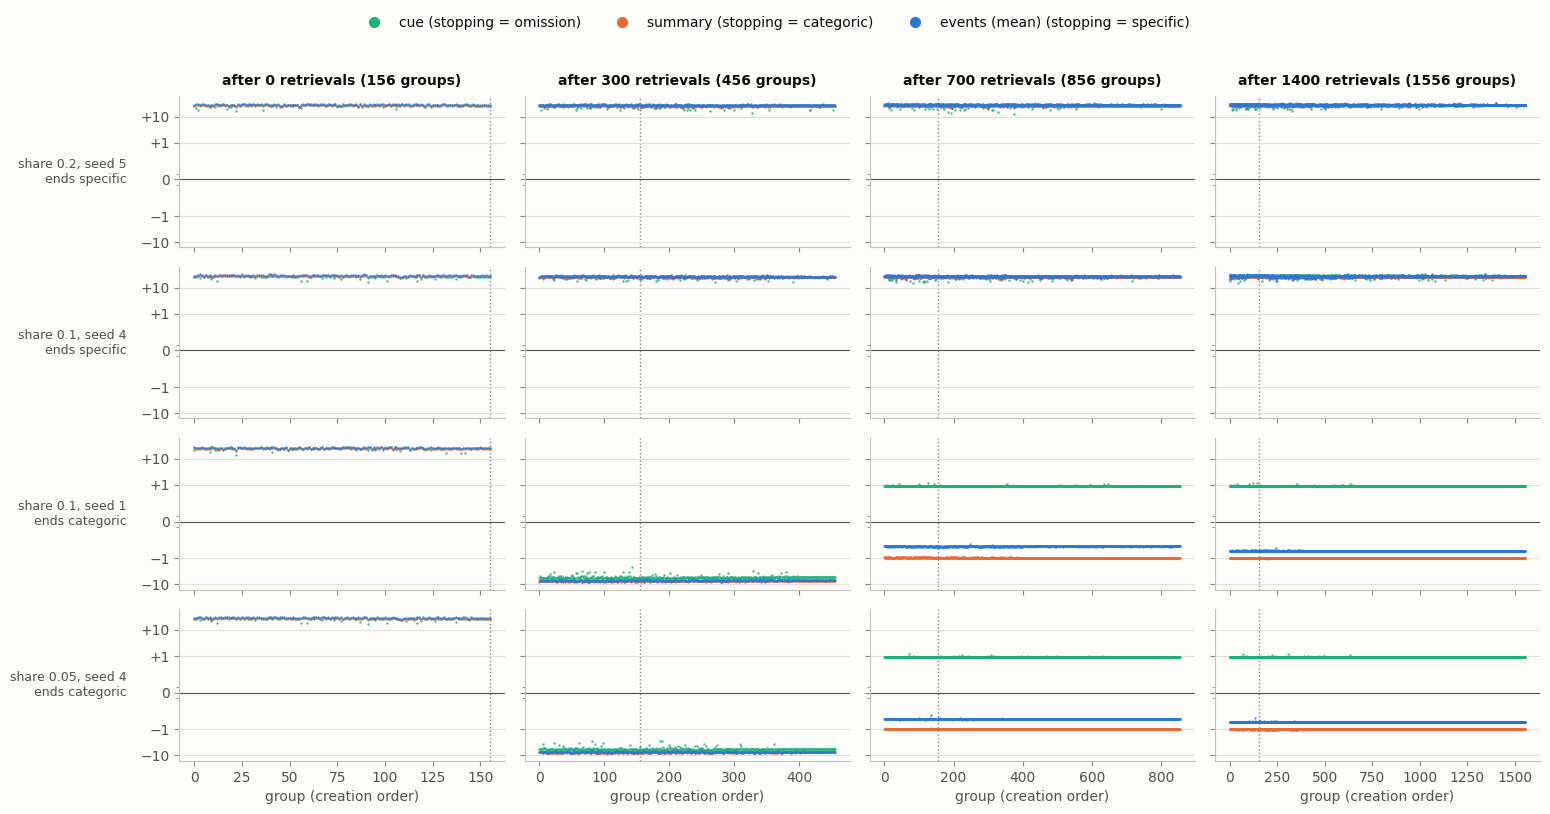

In [15]:
LEVELS = [("cue_q", 0.0, "omission", "cue"),
          ("summary_q", params["spectrum_summary_report"], "categoric", "summary"),
          ("event_q_mean", params["event_report"], "specific", "events (mean)")]
fig, axes = plt.subplots(len(runs), len(times), figsize=(3.9 * len(times), 2.0 * len(runs)),
                         sharex="col", sharey=True)
for r, run in enumerate(runs):
    for c, s in enumerate(run["snapshots"]):
        ax = axes[r, c]
        ag = pd.DataFrame(s["all_groups"]).sort_values("group")
        for col_name, report, outcome, _ in LEVELS:
            ax.scatter(ag["group"], ag[col_name] - report, s=3, color=OUTCOME_COLORS[outcome],
                       linewidths=0, alpha=0.8, zorder=3)
        ax.axhline(0, color=INK_2, lw=0.8, zorder=2)
        ax.axvline(s["trauma_group"], color=MUTED, lw=1, ls=":", zorder=1)
        ax.set_yscale("symlog", linthresh=0.5)
        ax.set_yticks([-10, -1, 0, 1, 10], labels=["−10", "−1", "0", "+1", "+10"])
        ax.grid(axis="y", which="minor", visible=False)
        if r == 0:
            ax.set_title(f"after {s['t']} retrievals ({s['n_groups']} groups)", pad=8)
        if r == len(runs) - 1:
            ax.set_xlabel("group (creation order)")
        if c == 0:
            ax.set_ylabel(run_label(run), fontsize=9, rotation=0, ha="right", va="center", labelpad=10)
handles = [plt.Line2D([], [], ls="", marker="o", color=OUTCOME_COLORS[o]) for _, _, o, _ in LEVELS]
fig.legend(handles, [f"{lab} (stopping = {o})" for _, _, o, lab in LEVELS], ncol=3,
           loc="upper center", bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**What the searches look like.** The next few retrievals after each snapshot, one row each, read left to right: the cue (square at step 0), then every memory the search visited (square = summary node, circle = event), coloured by the advantage of continuing there (same scale; values taken just after these retrievals). A tick above the row marks a step into a different group; ringed points are the trauma memory. The large marker at the end is the answer given (outcome colour); an omission ends at the cue. Searches that never stop on their own run to the 50-step cap. The table counts, per run and outcome, how many groups a search passed through and whether the memory reported belongs to the cued group.

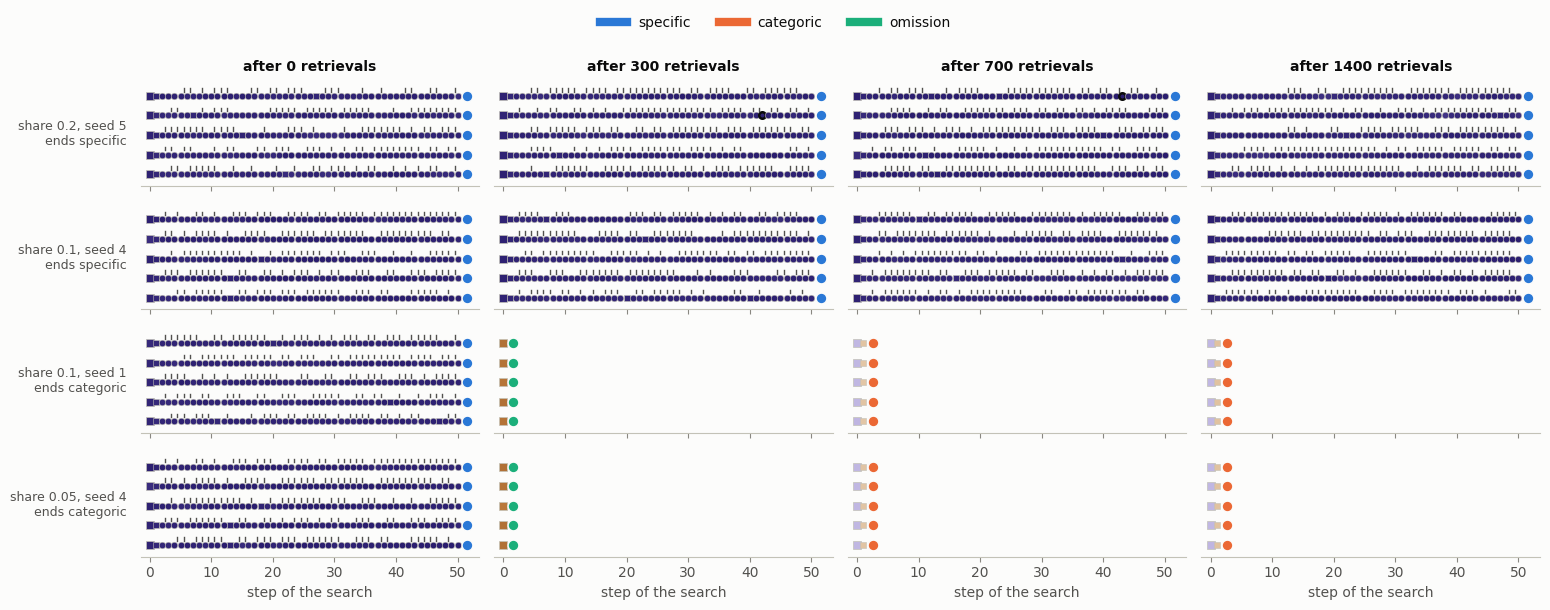

searches  mean_steps  \
run                                outcome                           
share 0.2, seed 5, ends specific   specific         20        50.0   
share 0.1, seed 4, ends specific   specific         20        50.0   
share 0.1, seed 1, ends categoric  specific          5        50.0   
                                   omission          5         0.0   
                                   categoric        10         1.0   
share 0.05, seed 4, ends categoric specific          5        50.0   
                                   omission          5         0.0   
                                   categoric        10         1.0   

                                              mean_groups_visited  \
run                                outcome                          
share 0.2, seed 5, ends specific   specific                 29.35   
share 0.1, seed 4, ends specific   specific                 30.80   
share 0.1, seed 1, ends categoric  specific                 28.20   
                                   omission                  0.00   
                                   categoric                 1.00   
share 0.05, seed 4, ends categoric specific                 30.00   
                                   omission                  0.00   
                                   categoric                 1.00   

                                              answer_in_cued_group  \
run                                outcome                           
share 0.2, seed 5, ends specific   specific                    0.0   
share 0.1, seed 4, ends specific   specific                    0.0   
share 0.1, seed 1, ends categoric  specific                    0.0   
                                   omission                    0.0   
                                   categoric                   1.0   
share 0.05, seed 4, ends categoric specific                    0.0   
                                   omission                    0.0   
                                   categoric                   1.0   

                                              visited_trauma_memory  
run                                outcome                           
share 0.2, seed 5, ends specific   specific                       2  
share 0.1, seed 4, ends specific   specific                       0  
share 0.1, seed 1, ends categoric  specific                       0  
                                   omission                       0  
                                   categoric                      0  
share 0.05, seed 4, ends categoric specific                       0  
                                   omission                       0  
                                   categoric                      0

In [16]:
max_len = params["max_steps"]
fig, axes = plt.subplots(len(runs), len(times), figsize=(3.9 * len(times), 1.5 * len(runs)),
                         sharex=True, sharey=True)
for r, run in enumerate(runs):
    for c, s in enumerate(run["snapshots"]):
        ax = axes[r, c]
        for i, w in enumerate(s["walks"]):
            y = -i
            nodes = w["nodes"]
            ax.plot([0, len(nodes)], [y, y], color=GRID, lw=0.8, zorder=1)
            ax.scatter([0], [y], marker="s", s=28, c=[col(w["cue_q"])], edgecolors=AXIS,
                       linewidths=0.5, zorder=3)
            for k, n in enumerate(nodes, start=1):
                ax.scatter([k], [y], marker="s" if n["level"] == "summary" else "o", s=22,
                           c=[col(adv(n))], edgecolors=INK if n["trauma"] else AXIS,
                           linewidths=1.8 if n["trauma"] else 0.4, zorder=3)
                prev = w["cue_group"] if k == 1 else nodes[k - 2]["group"]
                if n["group"] != prev:
                    ax.plot([k - 0.5, k - 0.5], [y + 0.22, y + 0.4], color=INK_2, lw=1, zorder=2)
            ax.scatter([len(nodes) + 1.6], [y], s=60, color=OUTCOME_COLORS[w["outcome"]],
                       edgecolors="#fcfcfb", linewidths=1, zorder=3)
        ax.set_ylim(-len(s["walks"]) + 0.4, 0.7)
        ax.set_xlim(-1.5, max_len + 3.5)
        ax.set_yticks([])
        ax.grid(False)
        ax.spines["left"].set_visible(False)
        if r == 0:
            ax.set_title(f"after {s['t']} retrievals", pad=8)
        if r == len(runs) - 1:
            ax.set_xlabel("step of the search")
        if c == 0:
            ax.set_ylabel(run_label(run), fontsize=9, rotation=0, ha="right", va="center", labelpad=10)
outcome_legend(fig)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

walk_rows = []
for run in runs:
    for s in run["snapshots"]:
        for w in s["walks"]:
            walk_rows.append({"run": run_label(run).replace("\n", ", "), "outcome": w["outcome"],
                              "steps": len(w["nodes"]), "groups": len({n["group"] for n in w["nodes"]}),
                              "in_cued_group": bool(w["nodes"]) and w["nodes"][-1]["group"] == w["cue_group"],
                              "trauma": any(n["trauma"] for n in w["nodes"])})
wr = pd.DataFrame(walk_rows)
display(wr.groupby(["run", "outcome"], sort=False).agg(
    searches=("steps", "size"), mean_steps=("steps", "mean"), mean_groups_visited=("groups", "mean"),
    answer_in_cued_group=("in_cued_group", "mean"), visited_trauma_memory=("trauma", "sum")).round(2))

## Notes

- These are simulations: confidence intervals shrink with more seeds, so read effect sizes, not significance.
- `w_bias` / `w_trauma` are snapshots after each retrieval; omissions teach the agent nothing, so flat stretches in the weights during omission phases are expected (only decay moves them).
- Configuration (network size, payoffs, learning rates, protocol lengths) is in `data/params.json` and at the top of `experiments.py`.